In [1]:
# !pip install -q huggingface_hub xarray netCDF4 h5netcdf scikit-image

In [2]:
# imports
import os, glob, tarfile
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import xarray as xr
from huggingface_hub import hf_hub_download

In [3]:
SEED = 42
PATCH= 128 #for U net
MIN_VALID= 0.5
NODATA= 255
IGNORE = 255
REF_ANGLE =35.0
rng=np.random.default_rng(SEED)


In [4]:
# data download
tar_path = hf_hub_download("Emulated-Inc/sci-sea-ice-charting-sar", "train.tar", repo_type="dataset")
tarfile.open(tar_path).extractall("data", filter="data")
files= sorted(glob.glob("data/**/*.nc", recursive=True))
print(len(files), "scenes.")

train.tar: reconstructing file:   0%|          |  0.00B /  989MB            

train.tar: downloading bytes:           |  0.00B            

347 scenes.


In [6]:
# checking one scene
ds=xr.open_dataset(files[0])
print(ds)

<xarray.Dataset> Size: 19MB
Dimensions:           (y: 995, x: 1040, y2km: 199, x2km: 208)
Dimensions without coordinates: y, x, y2km, x2km
Data variables: (12/26)
    hh                (y, x) float32 4MB ...
    hv                (y, x) float32 4MB ...
    incidence_angle   (y, x) float32 4MB ...
    distance_to_land  (y, x) uint8 1MB ...
    tb_6_9h           (y2km, x2km) float32 166kB ...
    tb_6_9v           (y2km, x2km) float32 166kB ...
    ...                ...
    t2m               (y2km, x2km) float32 166kB ...
    skt               (y2km, x2km) float32 166kB ...
    tcwv              (y2km, x2km) float32 166kB ...
    tclw              (y2km, x2km) float32 166kB ...
    SIC               (y, x) uint8 1MB ...
    SOD               (y, x) uint8 1MB ...
Attributes:
    scene_id:                2018_cis_001
    year:                    2018
    ice_service:             cis
    pixel_spacing_m:         400
    coarse_pixel_spacing_m:  2000


In [8]:
# checking values
for v in ["hh", "hv", "incidence_angle", "SOD"]:
    a=ds[v].values
    print(v, np.nanmin(a), np.nanmedian(a), np.nanmax(a))

hh -32.203125 -23.296875 3.5703125
hv -31.921875 -28.085938 -6.875
incidence_angle 21.421875 35.578125 46.453125
SOD 0 0.0 255


hh and hv seems to be already in dB( mostly negative, around -23 and -28). incidence angle ranges from 21 to 46 degrees, normal for Sentinal-1. this is a wide range, normalization should matter. SOD mediun is 0, so most of this scene is open water, and 255 marks no data

In [9]:
# counting ice type codes
counts= Counter()
for f in files:
    with xr.open_dataset(f) as d:
        counts.update(d["SOD"].values.ravel().tolist())

for k in sorted(counts):
    print(k, counts[k])

0 122693196
1 3725194
2 6131628
3 4317677
4 25102302
5 14274405
255 173694248


In [3]:
# naming the class names for better understanding
# naming the class names for better understanding
CLASS_NAMES = ["open water", "new ice", "young ice", "thin FYI", "thick FYI", "old ice"]  # FYI: First Year Ice
K = len(CLASS_NAMES)

rng = np.random.default_rng(SEED)
idx = rng.permutation(len(files))
n_val = int(0.2 * len(files))                   # 20% of 347 = 69 scenes
val_files   = [files[i] for i in idx[:n_val]]   # first 69 shuffled scenes -> validation
train_files = [files[i] for i in idx[n_val:]]   # remaining 278 scenes -> training
print(len(train_files), "training scenes.")
print(len(val_files), "validation scenes.")

Mounted at /content/drive
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


spliting by scene, not patches. patches cut from the same scene look very similar. if some patches from a scene were in trainng and others in validation, the model would be tested on almost seen data, and the scores would look better than they really are. splitnig the whole scene keeps the test honest.

In [12]:
# loading each scene and cutting
def make_patches(file_list, size=128):
    X, Y = [], []
    for f in file_list:
        d = xr.open_dataset(f)
        x = np.stack([d.hh.values, d.hv.values, d.incidence_angle.values], axis=-1)
        y = d.SOD.values.copy()
        d.close()

        y[np.isnan(x).any(axis=-1)] = 255     # no radar data= no label
        x = np.nan_to_num(x)

        for i in range(0, y.shape[0] - size + 1, size):
            for j in range(0, y.shape[1] - size + 1, size):
                py = y[i:i+size, j:j+size]
                if (py != 255).mean() >= 0.5:  # keeping patches that are at least half labelled
                    X.append(x[i:i+size, j:j+size])
                    Y.append(py)
    return np.array(X, dtype="float32"), np.array(Y)

X_train, Y_train = make_patches(train_files)
X_val,   Y_val   = make_patches(val_files)
print("Train:", X_train.shape, " Val:", X_val.shape)

Train: (8013, 128, 128, 3)  Val: (1945, 128, 128, 3)


In [14]:
from skimage.feature import graycomatrix, graycoprops

# 1. picking pixels
def sample_pixels(Y, n_draw, seed, per_class=None):
    rng = np.random.default_rng(seed)
    n = rng.integers(0, len(Y), n_draw)
    r = rng.integers(5, 123, n_draw)
    c = rng.integers(5, 123, n_draw)
    lab = Y[n, r, c]
    keep = lab != 255
    n, r, c, lab = n[keep], r[keep], c[keep], lab[keep]
    if per_class:
        pick = np.concatenate([np.flatnonzero(lab == k)[:per_class] for k in range(K)])
        n, r, c, lab = n[pick], r[pick], c[pick], lab[pick]
    return n, r, c, lab

tr_n, tr_r, tr_c, tr_y = sample_pixels(Y_train, 2_000_000, seed=1, per_class=1000)
va_n, va_r, va_c, va_y = sample_pixels(Y_val, 20_000, seed=2)

# 2. measuring texture
def texture(win):
    q = np.clip((win + 40) / 40 * 31, 0, 31).astype(np.uint8)
    g = graycomatrix(q, [1], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=32, symmetric=True, normed=True)
    return [graycoprops(g, p).mean() for p in ["contrast", "homogeneity", "correlation", "energy"]]

def features(X, n, r, c):
    rows = []
    for a, b, d in zip(n, r, c):
        win = X[a, b-5:b+6, d-5:d+6]
        rows.append([X[a, b, d, 0], X[a, b, d, 1]] + texture(win[..., 0]) + texture(win[..., 1]))
    return np.nan_to_num(rows)

F_train = features(X_train, tr_n, tr_r, tr_c)
F_val   = features(X_val, va_n, va_r, va_c)
print(F_train.shape, F_val.shape)

(6000, 10) (18255, 10)


In [25]:
from google.colab import drive
import os
drive.mount("/content/drive")

SAVE = "/content/drive/MyDrive/sea_ice/"
os.makedirs(SAVE, exist_ok=True)

np.savez(SAVE + "patches.npz", X_train=X_train, Y_train=Y_train, X_val=X_val, Y_val=Y_val)
np.savez(SAVE + "pixels.npz", F_train=F_train, F_val=F_val, tr_y=tr_y, va_y=va_y,
         tr_n=tr_n, tr_r=tr_r, tr_c=tr_c, va_n=va_n, va_r=va_r, va_c=va_c, svm_pred=svm_pred)
print("Saved")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved


In [18]:
# svm
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# svm for brightness only
svm_bs = make_pipeline(StandardScaler(), SVC(class_weight="balanced"))
svm_bs.fit(F_train[:, :2], tr_y)
svm_bs_pred=svm_bs.predict(F_val[:, :2])
print(classification_report(va_y, svm_bs_pred, target_names=CLASS_NAMES, zero_division=0))

print("~~~~~~~~~~~~~~~~~~~~~~~~")

# svm for brightness and texture
svm= make_pipeline(StandardScaler(), SVC(class_weight="balanced"))
svm.fit(F_train, tr_y)
svm_pred= svm.predict(F_val)
print(classification_report(va_y, svm_pred, target_names=CLASS_NAMES, zero_division=0))


              precision    recall  f1-score   support

  open water       0.91      0.57      0.70     11429
     new ice       0.05      0.34      0.08       644
   young ice       0.21      0.41      0.28      1045
    thin FYI       0.18      0.44      0.26       725
   thick FYI       0.21      0.07      0.10      2258
     old ice       0.61      0.54      0.57      2154

    accuracy                           0.48     18255
   macro avg       0.36      0.40      0.33     18255
weighted avg       0.69      0.48      0.55     18255

~~~~~~~~~~~~~~~~~~~~~~~~
              precision    recall  f1-score   support

  open water       0.94      0.89      0.91     11429
     new ice       0.11      0.30      0.17       644
   young ice       0.25      0.25      0.25      1045
    thin FYI       0.22      0.58      0.32       725
   thick FYI       0.28      0.14      0.18      2258
     old ice       0.74      0.60      0.66      2154

    accuracy                           0.69     1825

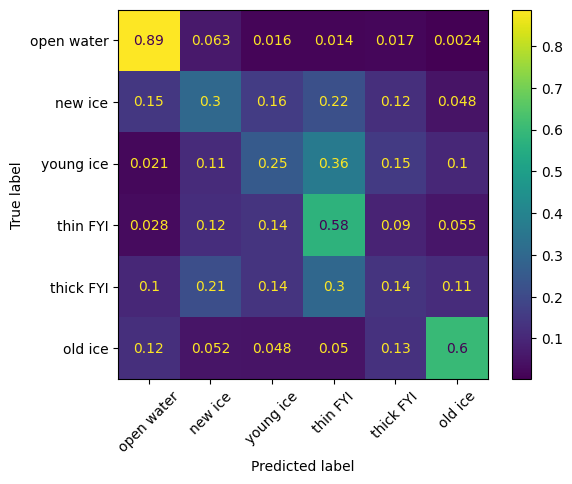

In [20]:
# confusion matrix of right and wrong guesses
ConfusionMatrixDisplay.from_predictions(va_y, svm_pred, display_labels=CLASS_NAMES, normalize="true", xticks_rotation=45)
plt.show()

***** *The next part is Deep Learning. Unlike SVM, it looks at the picture at once and learns its own texture patterns* *****

In [4]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# average and spread of HH, HV, angle (to scale the inputs)
s = X_train[tr_n, tr_r, tr_c]
MEAN, STD = s.mean(0), s.std(0)

# weight per ice type: rare types count more
counts = np.bincount(Y_train[Y_train != 255], minlength=K)
class_w = 1 / np.sqrt(counts / counts.sum())
class_w /= class_w.mean()
print(dict(zip(CLASS_NAMES, class_w.round(2))))

# lookup table: code -> weight (no-data 255 gets weight 0)
lut = np.zeros(256, dtype="float32")
lut[:K] = class_w

W_train, W_val = lut[Y_train], lut[Y_val]  # weight of every pixel
Yc_train, Yc_val = np.where(Y_train == 255, 0, Y_train), np.where(Y_val == 255, 0, Y_val)  # 255 -> 0 (ignored anyway)

{'open water': np.float64(0.23), 'new ice': np.float64(1.72), 'young ice': np.float64(1.23), 'thin FYI': np.float64(1.53), 'thick FYI': np.float64(0.54), 'old ice': np.float64(0.75)}


In [5]:
# unet~
inp = layers.Input((128, 128, 3))
x = layers.Normalization(mean=MEAN, variance=STD**2)(inp)

# down
d1 = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
d2 = layers.Conv2D(64, 3, padding="same", activation="relu")(layers.MaxPooling2D()(d1))

# bottom
mid = layers.Conv2D(128, 3, padding="same", activation="relu")(layers.MaxPooling2D()(d2))

# up
u2 = layers.Conv2D(64, 3, padding="same", activation="relu")(layers.Concatenate()([layers.UpSampling2D()(mid), d2]))
u1 = layers.Conv2D(32, 3, padding="same", activation="relu")(layers.Concatenate()([layers.UpSampling2D()(u2), d1]))

out = layers.Conv2D(K, 1, activation="softmax")(u1)

unet = Model(inp, out)
unet.compile(optimizer="adam", loss="sparse_categorical_crossentropy")

In [6]:
# Train
history = unet.fit(
    X_train, Yc_train, sample_weight=W_train, # study: pictures, answers, importance
    validation_data=(X_val, Yc_val, W_val), # checking progress on unseen scenes
    epochs=30, batch_size=32,
    callbacks=[
        tf.keras.callbacks.ReduceLROnPlateau(patience=2), # slow down learning when stuck
        tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),  # stop when no longer improving
    ],
)

Epoch 1/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 51s 139ms/step - loss: 0.4130 - val_loss: 0.6010 - learning_rate: 0.0010
Epoch 2/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 19s 76ms/step - loss: 0.3470 - val_loss: 0.5603 - learning_rate: 0.0010
Epoch 3/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 19s 77ms/step - loss: 0.3230 - val_loss: 0.5649 - learning_rate: 0.0010
Epoch 4/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 19s 77ms/step - loss: 0.3098 - val_loss: 0.5514 - learning_rate: 0.0010
Epoch 5/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 19s 77ms/step - loss: 0.2999 - val_loss: 0.5550 - learning_rate: 0.0010
Epoch 6/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 21s 83ms/step - loss: 0.2979 - val_loss: 0.5291 - learning_rate: 0.0010
Epoch 7/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 20s 78ms/step - loss: 0.2909 - val_loss: 0.5320 - learning_rate: 0.0010
Epoch 8/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 20s 79ms/step - loss: 0.2886 - val_loss: 0.5454 - learning_rate: 0.0010
Epoch 9/30
251/251 ━━━━━━━━━━━━━━━━━━━━ 20s 79ms/step - loss: 0.2691 - val_loss: 0.5188 - learning_rate

61/61 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step
              precision    recall  f1-score   support

  open water       0.95      0.97      0.96     11429
     new ice       0.11      0.00      0.01       644
   young ice       0.26      0.18      0.21      1045
    thin FYI       0.24      0.14      0.18       725
   thick FYI       0.38      0.53      0.44      2258
     old ice       0.68      0.72      0.70      2154

    accuracy                           0.78     18255
   macro avg       0.44      0.42      0.42     18255
weighted avg       0.75      0.78      0.76     18255



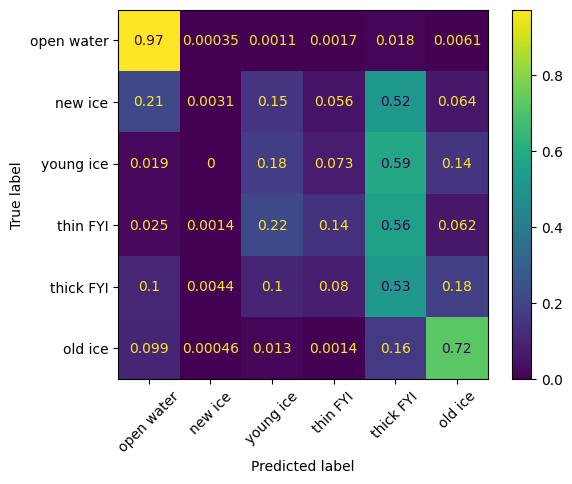

In [7]:
# comparison
pred_val= unet.predict(X_val, batch_size=32).argmax(-1)
unet_pred=pred_val[va_n, va_r, va_c]
print(classification_report(va_y, unet_pred, target_names=CLASS_NAMES, zero_division=0))
ConfusionMatrixDisplay.from_predictions(va_y, unet_pred, display_labels=CLASS_NAMES, normalize="true", xticks_rotation=45)
plt.show()

In [8]:
# saving model and result
unet.save(SAVE+"unet.keras")
np.savez(SAVE+"unet_pred.npz", pred_val=pred_val)
print("saved.")

saved.


In [9]:
plt.savefig("svm_confusion.png", dpi=150, bbox_inches="tight")   # in the SVM cell
plt.savefig("unet_confusion.png", dpi=150, bbox_inches="tight")  # in the U-Net cell

<Figure size 640x480 with 0 Axes>